# Telco Customer Churn Analysis

**Business question:** Which customers are most likely to leave, and what can the company do to retain them?

**Dataset:** Telco Customer Churn (IBM sample dataset), 7,043 customers and 21 columns. The target column is `Churn` (whether the customer left).

**Tools:** Python, pandas, Matplotlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.shape)

(7043, 21)


## 1. Data Inspection and Cleaning

`df.info()` shows that `TotalCharges` is stored as text (`object`) even though it should be numeric. This suggests hidden non-numeric values, so I check it before analysis.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
print((df["TotalCharges"].str.strip() == "").sum())

11


In [7]:
df["TotalCharges"] =pd.to_numeric(df["TotalCharges"],errors="coerce")

In [8]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Converting `TotalCharges` to numbers revealed **11 missing values**, which were hidden as blank spaces. All 11 customers have `tenure = 0` (new customers with no billing yet).
So I dropped them, leaving 7,032 customers.

In [9]:
#delete the 11 rows with null TotalCharges 
df=df.dropna(subset=["TotalCharges"])
print(df.shape)


(7032, 21)


### Data Quality Checks

I checked for duplicate rows and duplicate customer IDs, then verified that categorical columns have consistent values.

In [10]:
print(df.duplicated().sum())          
print(df["customerID"].duplicated().sum())

0
0


In [11]:
for col in ["gender", "Partner", "Dependents", "PhoneService","InternetService", "Contract", "PaymentMethod", "Churn"]:
    print(col,df[col].unique())
    

gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
Contract ['Month-to-month' 'One year' 'Two year']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']


In [12]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


## 2. Overall Churn Rate

In [13]:
print(df["Churn"].value_counts())


Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [14]:
print(df["Churn"].value_counts(normalize=True)*100)


Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


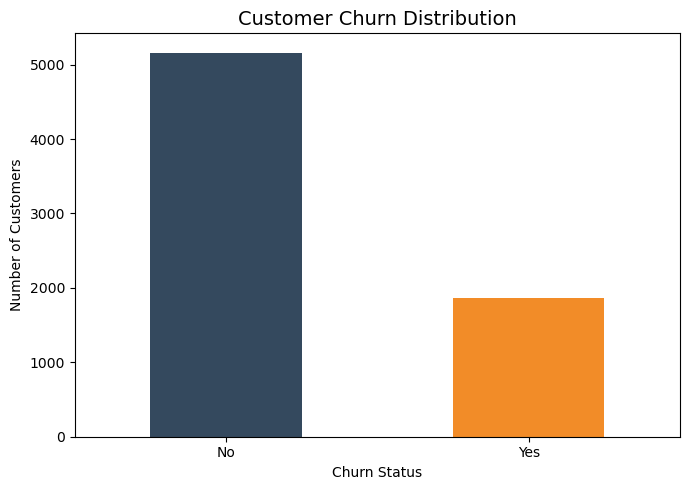

In [15]:
df["Churn"].value_counts().plot(
    kind="bar",
    color=["#34495E", "#F28C28"],
    figsize=(7, 5)
)

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

About **27%** of customers (1,869 out of 7,032) left the company, roughly one in four.

## 3. Churn by Contract Type

Does the contract type affect churn? I use `crosstab` with `normalize="index"` so each row shows the churn rate **within** that contract type (each row sums to 100%).

In [16]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print(contract_churn.round(1))

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


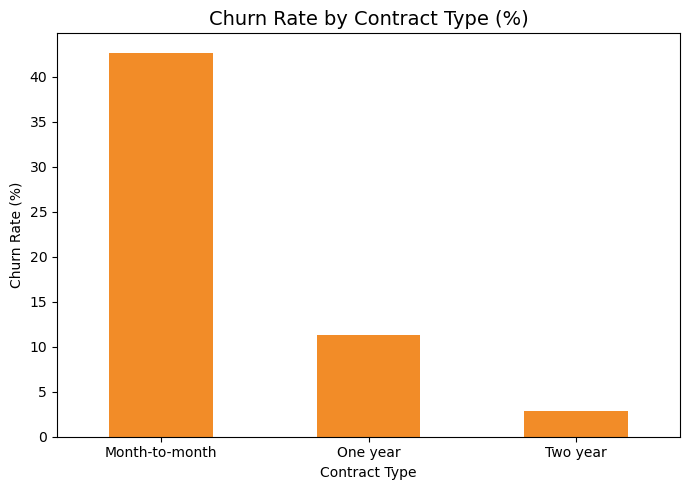

In [17]:
contract_churn["Yes"].plot(
    kind="bar",
    color="#F28C28",
    figsize=(7, 5)
)

plt.title("Churn Rate by Contract Type (%)", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Month-to-month customers churn at **42.7%**, compared with **11.3%** for one-year and **2.8%** for two-year contracts. Separately, month-to-month is also the most common contract: about **55%** of all customers (3,875 out of 7,032) are on it, whether they left or stayed. This makes it the largest and riskiest group.


## 4. Churn by Tenure

`tenure` is the number of months a customer has been with the company. It ranges from 1 to 72, so I group it into four ranges to make comparison easier.

In [18]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)
print(df["tenure_group"].value_counts().sort_index())

tenure_group
0-12     2175
13-24    1024
25-48    1594
49-72    2239
Name: count, dtype: int64


In [19]:
tenure_churn = pd.crosstab(df["tenure_group"], df["Churn"], normalize="index") * 100
print(tenure_churn.round(1))

Churn           No   Yes
tenure_group            
0-12          52.3  47.7
13-24         71.3  28.7
25-48         79.6  20.4
49-72         90.5   9.5


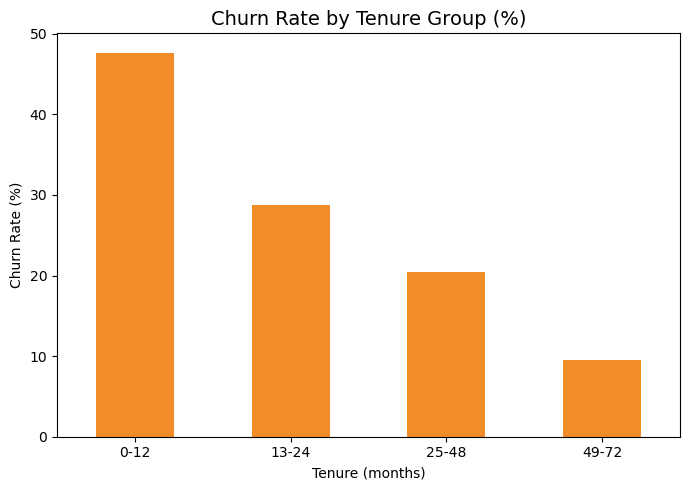

In [20]:
tenure_churn["Yes"].plot(
    kind="bar",
    color="#F28C28",
    figsize=(7, 5)
)

plt.title("Churn Rate by Tenure Group (%)", fontsize=14)
plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn is highest in the first year (**47.7%**) and falls steadily as tenure grows, down to **9.5%** for customers with more than four years. The first 12 months are the most critical period for retention.

## 5. Contract Type and Tenure Together

Contract type and tenure measure different things. **Contract** is the plan the customer is on now (month-to-month, one year, or two year), while **tenure** is how many months they have been with the company in total.I check both together to see which group is really at risk.

In [21]:
print((pd.crosstab([df["Contract"], df["tenure_group"]], df["Churn"], normalize="index") * 100).round(1))

Churn                           No   Yes
Contract       tenure_group             
Month-to-month 0-12           48.6  51.4
               13-24          62.3  37.7
               25-48          67.1  32.9
               49-72          74.0  26.0
One year       0-12           89.4  10.6
               13-24          91.9   8.1
               25-48          89.4  10.6
               49-72          87.1  12.9
Two year       0-12          100.0   0.0
               13-24         100.0   0.0
               25-48          97.8   2.2
               49-72          96.7   3.3


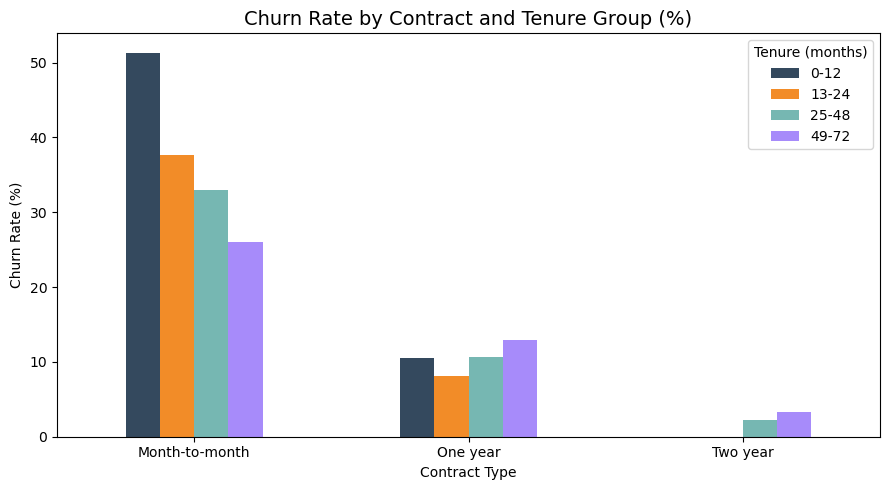

In [22]:
combo = pd.crosstab(
    [df["Contract"], df["tenure_group"]],
    df["Churn"],
    normalize="index"
)["Yes"] * 100

combo.unstack().plot(
    kind="bar",
    figsize=(9, 5),
    color=["#34495E", "#F28C28", "#76B7B2", "#A78BFA"]
)

plt.title("Churn Rate by Contract and Tenure Group (%)", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Tenure (months)")
plt.tight_layout()
plt.show()

The highest-risk group is **new customers on a month-to-month contract**: about **51%** of them left. Even within month-to-month, churn falls as tenure grows, to about **26%** for customers with more than four years.

One-year and two-year contracts have low churn across all tenure groups. Two-year customers in their first two years show no churn at all, but this group is small, so I avoid drawing strong conclusions from it.

## 6. Customer Profile

Which customer groups churn more? I compare churn rates for senior citizens, customers with and without a partner, and customers with and without dependents.

In [23]:
for col in ["SeniorCitizen", "Partner", "Dependents"]:
    counts = pd.crosstab(df[col], df["Churn"])
    rates = (pd.crosstab(df[col], df["Churn"], normalize="index") * 100).round(1)
    print(pd.concat([counts, rates], axis=1, keys=["Count", "Rate %"]))
    print("-" * 30)

              Count       Rate %      
Churn            No   Yes     No   Yes
SeniorCitizen                         
0              4497  1393   76.3  23.7
1               666   476   58.3  41.7
------------------------------
        Count       Rate %      
Churn      No   Yes     No   Yes
Partner                         
No       2439  1200   67.0  33.0
Yes      2724   669   80.3  19.7
------------------------------
           Count       Rate %      
Churn         No   Yes     No   Yes
Dependents                         
No          3390  1543   68.7  31.3
Yes         1773   326   84.5  15.5
------------------------------


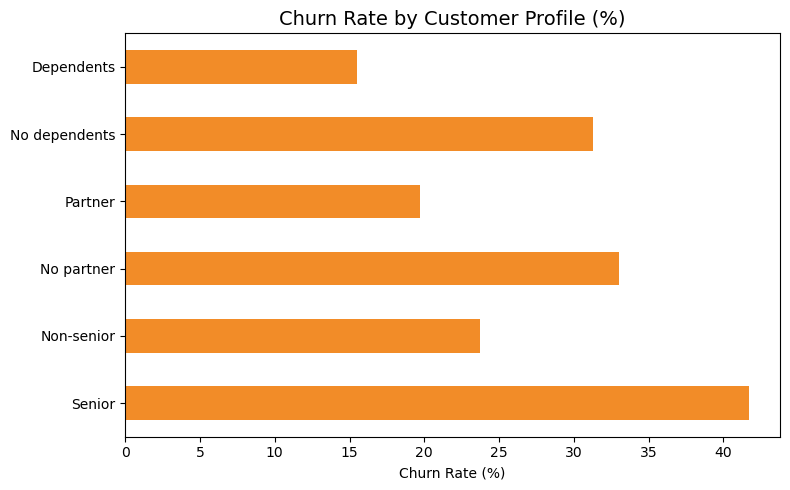

In [24]:
# Values copied from the churn-rate tables above
rates = {
    "Senior": 41.7,
    "Non-senior": 23.7,
    "No partner": 33.0,
    "Partner": 19.7,
    "No dependents": 31.3,
    "Dependents": 15.5,
}

pd.Series(rates).plot(
    kind="barh",
    color="#F28C28",
    figsize=(8, 5)
)

plt.title("Churn Rate by Customer Profile (%)", fontsize=14)
plt.xlabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


Churn is higher among senior citizens (**41.7%** vs 23.7%), customers without a partner (**33.0%** vs 19.7%), and customers without dependents (**31.3%** vs 15.5%).

Senior citizens have the highest churn rate, but they are a small group (1,142 customers). Most customers who left (1,393 out of 1,869) are not senior citizens. 


## 7. Key Findings and Recommendations

**Findings**
- About 27% of customers left (1,869 out of 7,032).
- Month-to-month contracts have the highest churn (42.7%).
- Churn is highest in the first year (47.7%) and falls as tenure grows.
- The highest-risk group is customers in their first year on a month-to-month contract (51.4% churn).
- Churn is also higher among senior citizens and customers without a partner or dependents.

**Recommendations**
1. Make one-year and two-year plans more attractive.
2. Offer incentives to move first-year month-to-month customers to a one-year contract.
3. Run an onboarding and follow-up program during the first 12 months, when churn is highest (47.7%).
4. Create individual-focused offers for customers without a partner or dependents , and consider a dedicated offer for senior citizens.
5. Next step: survey customers who left to understand the reasons, since this data shows who churns but not why.


